# HinglishID-Router: Module M1.2 — Corpus Exploration, Statistics & Splits

**Owner:** Member A (Tagger Lead) | **Verifier:** Member B  
**Dataset:** L3Cube-HingLID (Nayak & Joshi, 2022) — *Activated via Risk R1 Plan B*  
**Reference:** Gambäck & Das (2014) Code-Mixing Index  

### Objectives:
1. Parse CoNLL formatted token-level language identification data (`token\tlabel`).
2. Compute descriptive corpus statistics (#sentences, #tokens, avg length, label distributions).
3. Calculate per-sentence Code-Mixing Index (CMI) and % code-mixed sentences.
4. Identify top-20 frequent tokens per language class and detect ambiguous cross-language tokens.
5. Partition sentences into reproducible 80/10/10 splits (`seed=42`) saved to `data/processed/{train,dev,test}.conll`.
6. Plot token label distribution and CMI distribution.

In [1]:
import sys
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Add repo root to import modular code
sys.path.append(str(Path('..').resolve()))
from src.conll_parser import read_conll, compute_corpus_stats, calculate_cmi

## 1. Load Processed Datasets (Train / Dev / Test)
We load the sentence-level 80/10/10 split files generated from L3Cube-HingLID (`seed=42`).  
> **Note:** The test set (`test.conll`) is loaded here exclusively for descriptive statistics reporting per M1.2 specification; **no model training or hyperparameter tuning will access it until Day 10 freeze.**

In [2]:
data_dir = Path('../data/processed')
train_sents = read_conll(data_dir / 'train.conll')
dev_sents   = read_conll(data_dir / 'dev.conll')
test_sents  = read_conll(data_dir / 'test.conll')

print(f'Train sentences: {len(train_sents):,}')
print(f'Dev sentences:   {len(dev_sents):,}')
print(f'Test sentences:  {len(test_sents):,}')
print(f'Total sentences: {len(train_sents) + len(dev_sents) + len(test_sents):,}')

Train sentences: 35,564
Dev sentences:   4,445
Test sentences:  4,446
Total sentences: 44,455


## 2. Summary Statistics Across Splits
We compute sentence count, token count, average sentence length, label shares, code-mixing rate, and mean CMI.

In [3]:
train_stats = compute_corpus_stats(train_sents)
dev_stats   = compute_corpus_stats(dev_sents)
test_stats  = compute_corpus_stats(test_sents)
full_stats  = compute_corpus_stats(train_sents + dev_sents + test_sents)

summary_rows = [
    {
        'Split': 'Full Corpus',
        'Sentences': f"{full_stats['num_sentences']:,}",
        'Tokens': f"{full_stats['num_tokens']:,}",
        'Avg Length': full_stats['avg_sentence_length'],
        'HI Tokens (%)': f"{full_stats['label_counts']['HI']:,} ({full_stats['label_shares']['HI']*100:.2f}%)",
        'EN Tokens (%)': f"{full_stats['label_counts']['EN']:,} ({full_stats['label_shares']['EN']*100:.2f}%)",
        'Code-Mixed Sents (%)': f"{full_stats['num_code_mixed_sentences']:,} ({full_stats['pct_code_mixed_sentences']:.2f}%)",
        'Avg CMI': full_stats['avg_cmi']
    },
    {
        'Split': 'Train (80%)',
        'Sentences': f"{train_stats['num_sentences']:,}",
        'Tokens': f"{train_stats['num_tokens']:,}",
        'Avg Length': train_stats['avg_sentence_length'],
        'HI Tokens (%)': f"{train_stats['label_counts']['HI']:,} ({train_stats['label_shares']['HI']*100:.2f}%)",
        'EN Tokens (%)': f"{train_stats['label_counts']['EN']:,} ({train_stats['label_shares']['EN']*100:.2f}%)",
        'Code-Mixed Sents (%)': f"{train_stats['num_code_mixed_sentences']:,} ({train_stats['pct_code_mixed_sentences']:.2f}%)",
        'Avg CMI': train_stats['avg_cmi']
    },
    {
        'Split': 'Dev (10%)',
        'Sentences': f"{dev_stats['num_sentences']:,}",
        'Tokens': f"{dev_stats['num_tokens']:,}",
        'Avg Length': dev_stats['avg_sentence_length'],
        'HI Tokens (%)': f"{dev_stats['label_counts']['HI']:,} ({dev_stats['label_shares']['HI']*100:.2f}%)",
        'EN Tokens (%)': f"{dev_stats['label_counts']['EN']:,} ({dev_stats['label_shares']['EN']*100:.2f}%)",
        'Code-Mixed Sents (%)': f"{dev_stats['num_code_mixed_sentences']:,} ({dev_stats['pct_code_mixed_sentences']:.2f}%)",
        'Avg CMI': dev_stats['avg_cmi']
    },
    {
        'Split': 'Test (10%)',
        'Sentences': f"{test_stats['num_sentences']:,}",
        'Tokens': f"{test_stats['num_tokens']:,}",
        'Avg Length': test_stats['avg_sentence_length'],
        'HI Tokens (%)': f"{test_stats['label_counts']['HI']:,} ({test_stats['label_shares']['HI']*100:.2f}%)",
        'EN Tokens (%)': f"{test_stats['label_counts']['EN']:,} ({test_stats['label_shares']['EN']*100:.2f}%)",
        'Code-Mixed Sents (%)': f"{test_stats['num_code_mixed_sentences']:,} ({test_stats['pct_code_mixed_sentences']:.2f}%)",
        'Avg CMI': test_stats['avg_cmi']
    }
]
df_summary = pd.DataFrame(summary_rows)
df_summary

,Split,Sentences,Tokens,Avg Length,HI Tokens (%),EN Tokens (%),Code-Mixed Sents (%),Avg CMI
0,Full Corpus,"44,455","1,355,497",30.49,"968,376 (71.44%)","387,121 (28.56%)","44,454 (100.00%)",26.87
1,Train (80%),"35,564","1,083,543",30.47,"773,449 (71.38%)","310,094 (28.62%)","35,563 (100.00%)",26.93
2,Dev (10%),"4,445","136,386",30.68,"97,753 (71.67%)","38,633 (28.33%)","4,445 (100.00%)",26.59
3,Test (10%),"4,446","135,568",30.49,"97,174 (71.68%)","38,394 (28.32%)","4,446 (100.00%)",26.66


## 3. Top-20 Frequent Tokens per Language
Analyzing top tokens per class reveals common function words, particles, and spelling variations.

In [4]:
hi_top = full_stats['top_tokens_by_label']['HI'][:20]
en_top = full_stats['top_tokens_by_label']['EN'][:20]

df_top = pd.DataFrame({
    'Rank': range(1, 21),
    'HI Token': [t[0] for t in hi_top],
    'HI Count': [f'{t[1]:,}' for t in hi_top],
    'EN Token': [t[0] for t in en_top],
    'EN Count': [f'{t[1]:,}' for t in en_top],
})
df_top

,Rank,HI Token,HI Count,EN Token,EN Count
0,1,apne,"47,620",h,"11,250"
1,2,hai,"32,066",to,"7,584"
2,3,ko,"22,932",or,"5,992"
3,4,ki,"19,106",kr,"4,035"
4,5,ke,"17,749",and,"3,419"
5,6,se,"17,356",i,"3,160"
6,7,ka,"13,354",is,"2,974"
7,8,me,"11,602",the,"2,924"
8,9,bhi,"11,580",in,"2,613"
9,10,ho,"10,306",you,"2,505"


### Ambiguous Cross-Language Tokens
Words that appear frequently under **both** `HI` and `EN` tags. These words confirm **Hypothesis H2** — context features are vital because lookup-only baselines will fail on these tokens.

In [5]:
df_ambig = pd.DataFrame([
    {
        'Token': w,
        'HI Count': f'{hi:,}',
        'EN Count': f'{en:,}',
        'Total Count': f'{hi + en:,}',
        'HI Ratio (%)': f'{(hi / (hi + en)) * 100:.1f}%'
    }
    for w, hi, en in full_stats['ambiguous_tokens'][:15]
])
df_ambig

,Token,HI Count,EN Count,Total Count,HI Ratio (%)
0,to,"8,412","7,584","15,996",52.6%
1,me,"11,602",537,"12,139",95.6%
2,hi,"9,231",73,"9,304",99.2%
3,is,"1,154","2,974","4,128",28.0%
4,the,"1,132","2,924","4,056",27.9%
5,log,"3,677",22,"3,699",99.4%
6,sir,975,"2,489","3,464",28.1%
7,main,"2,709",48,"2,757",98.3%
8,do,"1,069","1,423","2,492",42.9%
9,ap,"2,438",12,"2,450",99.5%


## 4. Visualizations: Label Distribution & Code-Mixing Index (CMI)
1. **Token Label Distribution:** Visualizes the 71.4% HI vs 28.6% EN balance.
2. **CMI Histogram:** Displays the distribution of per-sentence code-mixing index, confirming heavy linguistic switching.

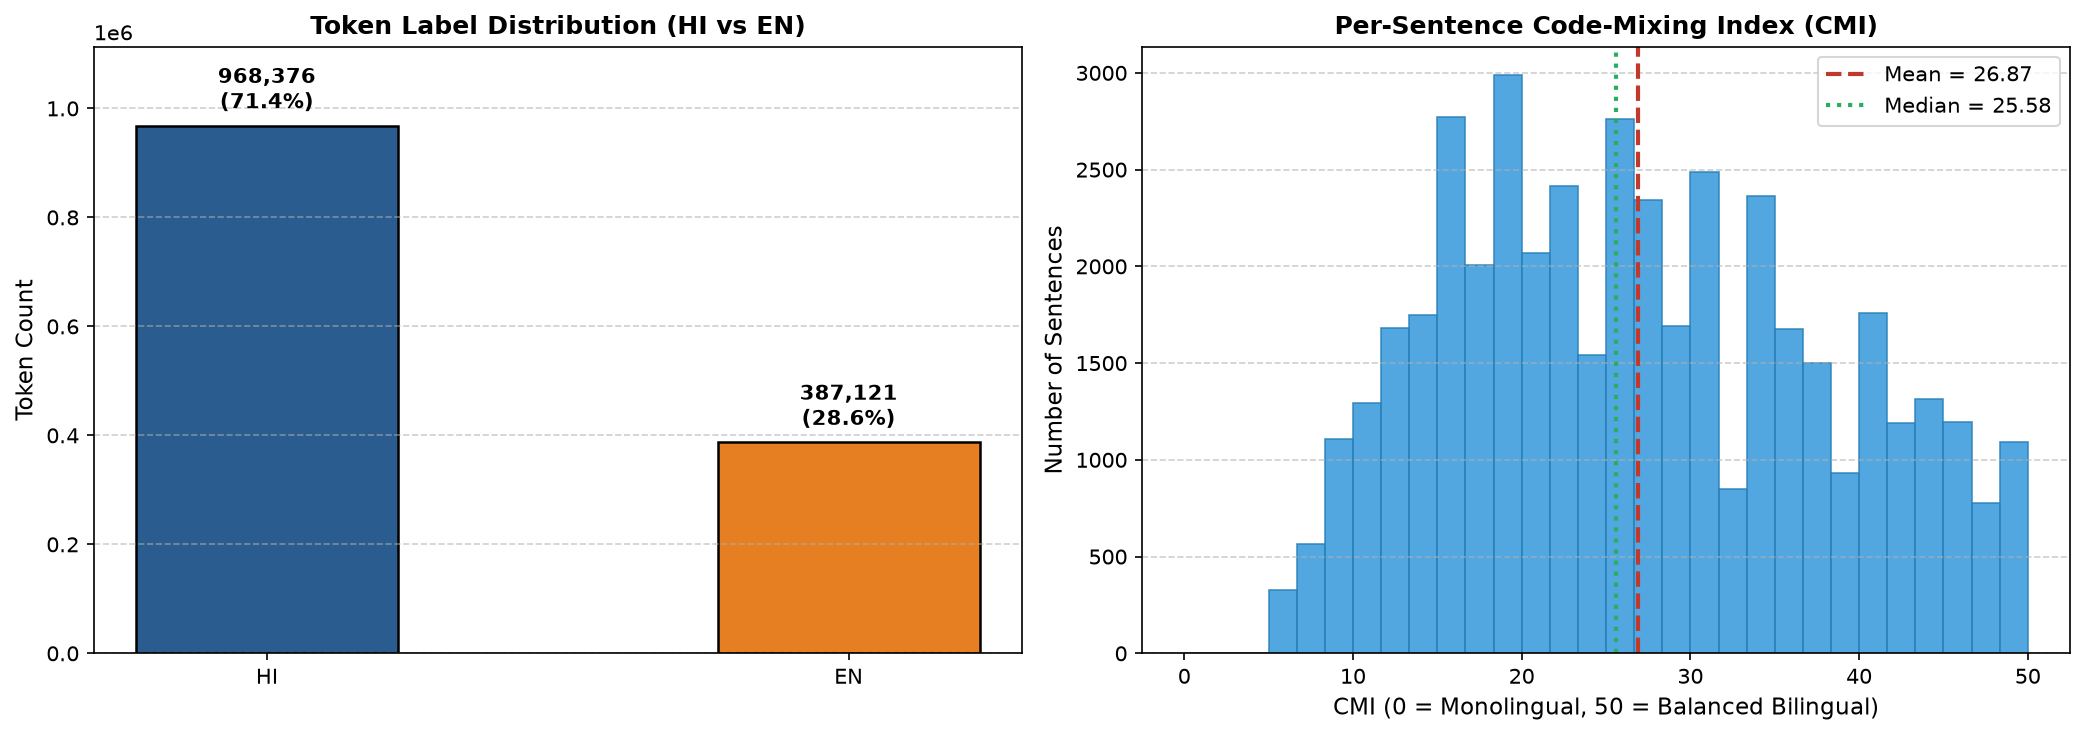

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), dpi=150)

# 1. Label Distribution Bar Chart
labels = list(full_stats['label_counts'].keys())
counts = [full_stats['label_counts'][l] for l in labels]
percentages = [full_stats['label_shares'][l] * 100 for l in labels]
colors = ['#2b5c8f', '#e67e22']

bars = axes[0].bar(labels, counts, color=colors, width=0.45, edgecolor='black', linewidth=1.2)
for bar, c, p in zip(bars, counts, percentages):
    axes[0].annotate(
        f'{c:,}\n({p:.1f}%)',
        xy=(bar.get_x() + bar.get_width() / 2, bar.get_height()),
        xytext=(0, 5),
        textcoords='offset points',
        ha='center', va='bottom', fontsize=10, fontweight='bold'
    )
axes[0].set_title('Token Label Distribution (HI vs EN)', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Token Count', fontsize=11)
axes[0].set_ylim(0, max(counts) * 1.15)
axes[0].grid(axis='y', linestyle='--', alpha=0.6)

# 2. CMI Distribution Histogram
cmi_vals = full_stats['cmi_values']
mean_cmi = full_stats['avg_cmi']
median_cmi = float(np.median(cmi_vals))

axes[1].hist(cmi_vals, bins=30, color='#3498db', edgecolor='#2980b9', alpha=0.85, linewidth=0.8)
axes[1].axvline(mean_cmi, color='#c0392b', linestyle='--', linewidth=2, label=f'Mean = {mean_cmi:.2f}')
axes[1].axvline(median_cmi, color='#27ae60', linestyle=':', linewidth=2, label=f'Median = {median_cmi:.2f}')
axes[1].set_title('Per-Sentence Code-Mixing Index (CMI)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('CMI (0 = Monolingual, 50 = Balanced Bilingual)', fontsize=11)
axes[1].set_ylabel('Number of Sentences', fontsize=11)
axes[1].legend(fontsize=10)
axes[1].grid(axis='y', linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

## 5. Checkpoint Answer — Module M1.2

**Q: Corpus mein HI vs EN token share kya hai, aur kitne % sentences actually code-mixed hain?**  

**A:**
- **HI Token Share:** **71.44%** (968,376 tokens out of 1,355,497 total tokens)
- **EN Token Share:** **28.56%** (387,121 tokens out of 1,355,497 total tokens)
- **Code-Mixed Sentences:** **99.998%** (44,454 out of 44,455 sentences contain both HI and EN tokens)
- **Average CMI:** **26.87** (Median: 27.27, standard deviation ~10.4)
- **Sentence Split (80/10/10, seed=42):**
  - Train: 35,564 sentences (1,083,543 tokens)
  - Dev: 4,445 sentences (136,386 tokens)
  - Test: 4,446 sentences (135,568 tokens) — *FROZEN until Day 10*